In [ ]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
import session_info
session_info.show()

In [1]:
sc.settings.verbosity = 3             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(dpi=200, facecolor='white', color_map = 'RdPu',)

In [ ]:
adata=sc.read_h5ad('/path/to/h5ad_annotated/_sc_ALL.h5ad')

In [ ]:
fib_mu=sc.read_h5ad('/path/to/h5ad_subcluster/fib_mu.h5ad')

In [ ]:
adata.obs['global_anno_level2'] = adata.obs['leiden_0.2_anno'].astype(str).copy()

smc_peri = fib_mu.obs.loc[fib_mu.obs['sub_anno'].isin(['SMC', 'Pericyte']), 'sub_anno']

stromal_idx = adata.obs.index[adata.obs['leiden_0.2_anno'] == 'Stromal']
target_idx = stromal_idx.intersection(smc_peri.index)

adata.obs.loc[target_idx, 'global_anno_level2'] = smc_peri.loc[target_idx].astype(str).values

adata.obs['global_anno_level2'] = adata.obs['global_anno_level2'].astype('category')

In [ ]:
del adata.obs['leiden_0.2_anno']

In [ ]:
rename_map = {
    'EC': 'Endothelial',
    'Pericyte': 'Mural',
    'SMC': 'Mural',
    'Epithelium':'Epithelial',
    'Plasma': 'B cell',
    'Mast':'Myeloid'
}

adata.obs['global_anno_level1'] = (
    adata.obs['global_anno_level2'].astype(str).replace(rename_map).astype('category')
)

adata.obs['global_anno_level1'].value_counts()


In [ ]:
order = ['Epithelial', 'T cell', 'B cell',  'Myeloid', 'Endothelial',
         'Fibroblast',  'Mural']

adata.obs['global_anno_level1'] = adata.obs['global_anno_level1'].cat.reorder_categories(order)
adata.obs['global_anno_level1'].cat.categories


# Fib.2b

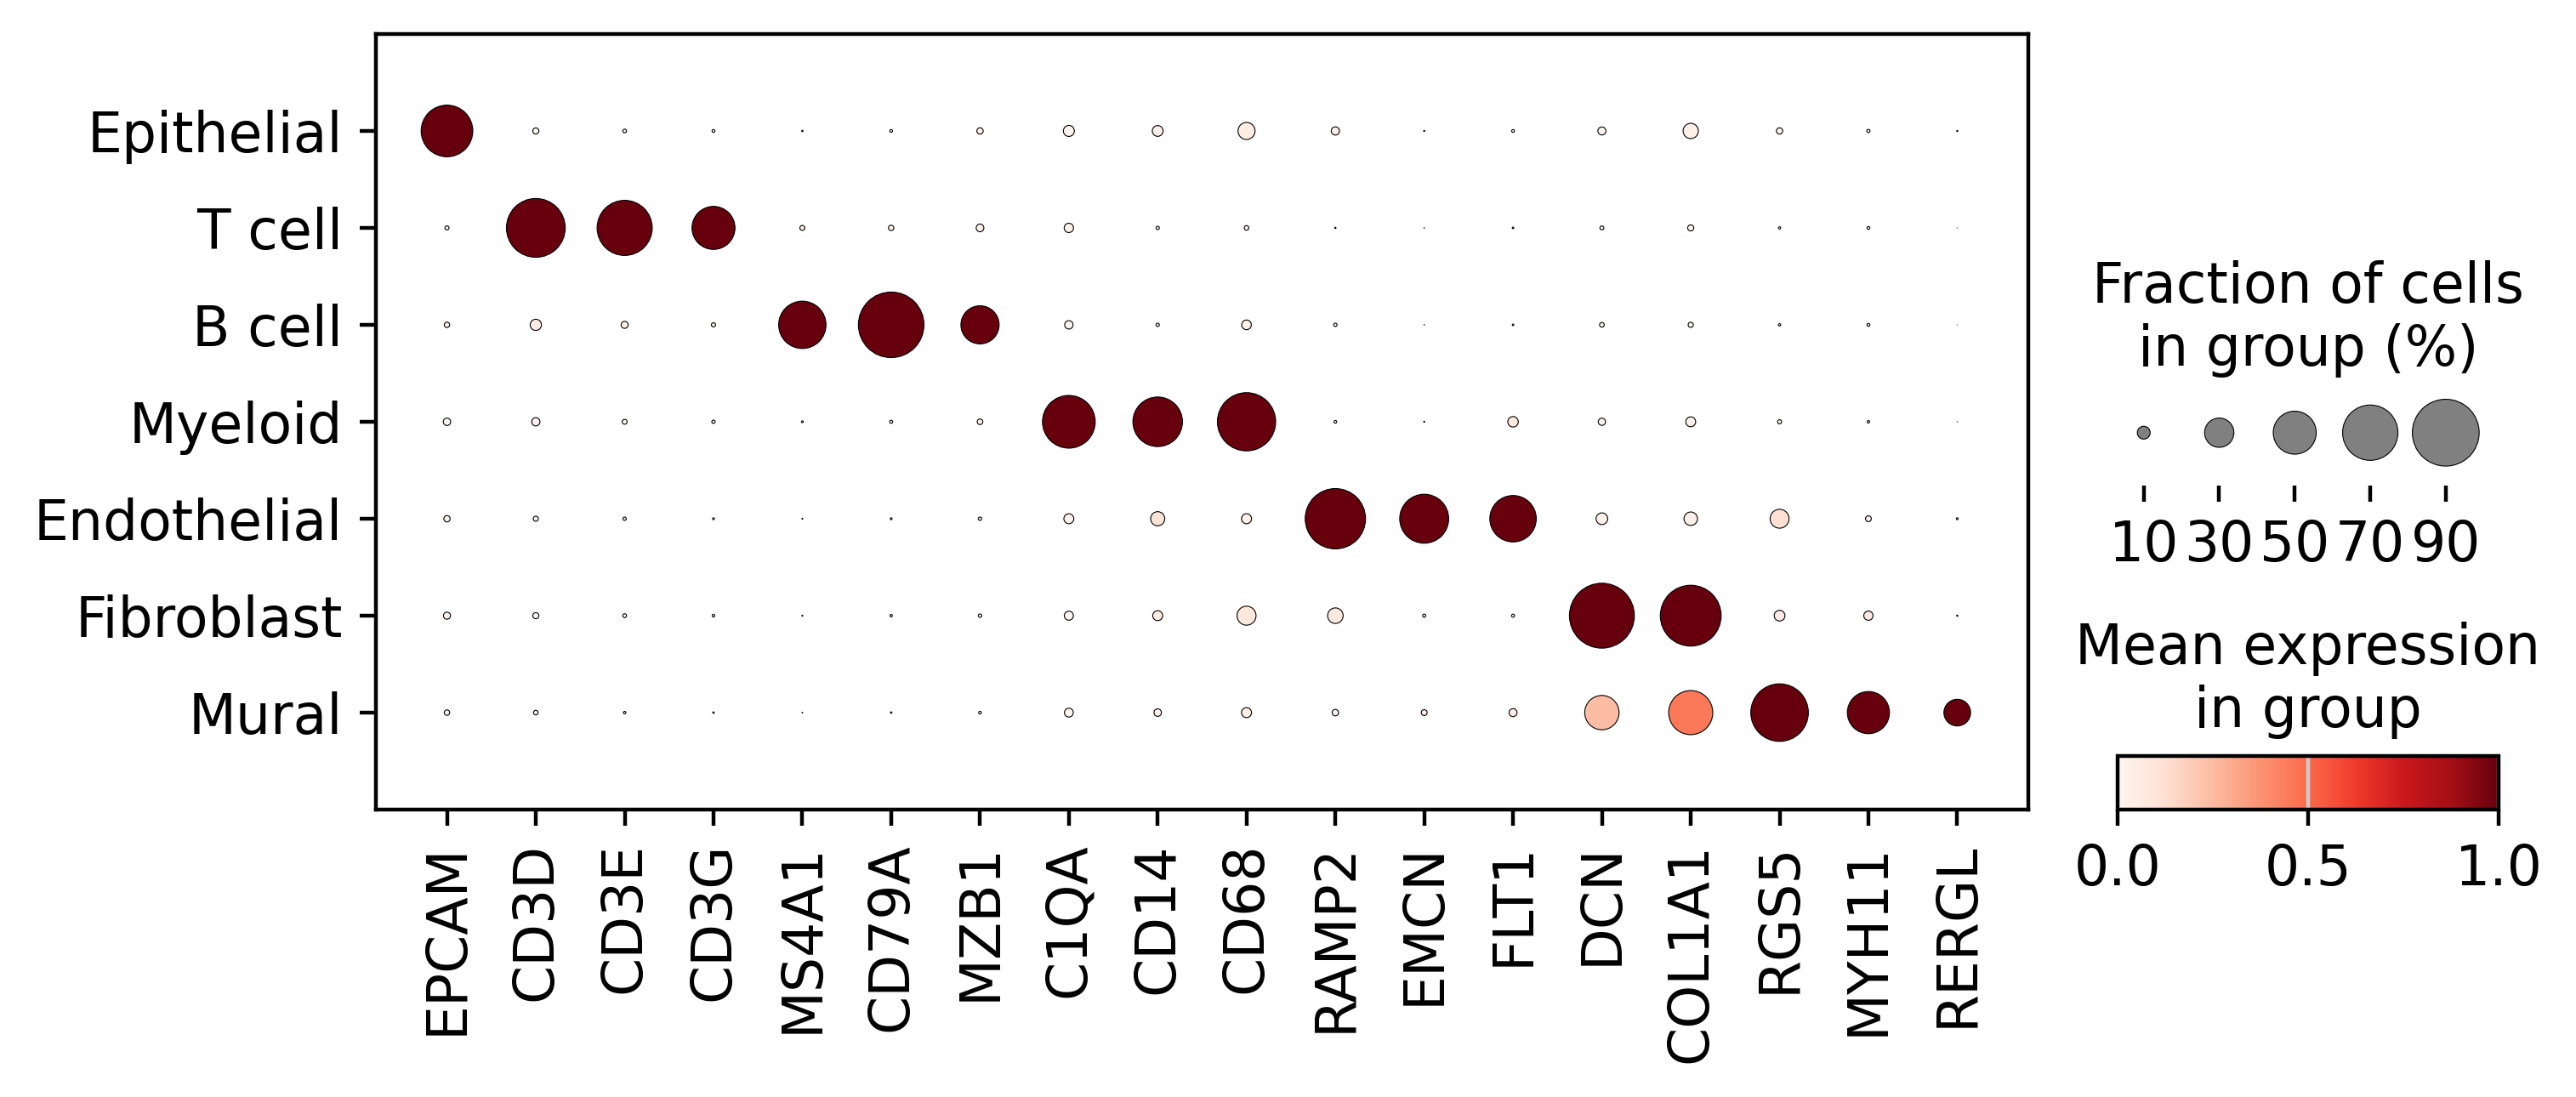

In [2]:
plt.rcParams['pdf.fonttype'] = 42   # Illustrator에서 글자 편집 가능하게
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']

dp = sc.pl.dotplot(adata, groupby='global_anno_level1',figsize=(8,3.5),
                   var_names=['EPCAM',
                                        'CD3D','CD3E','CD3G',
                                        'MS4A1','CD79A','MZB1',
                                        
                                        'C1QA','CD14','CD68',
                                        'RAMP2','EMCN','FLT1',
                                        'DCN','COL1A1',
                                        'RGS5','MYH11','RERGL',],
                   standard_scale='var',
                   return_fig=True)

dp.make_figure()
plt.savefig('Fig_2b.pdf', dpi=700, bbox_inches='tight')
plt.show()


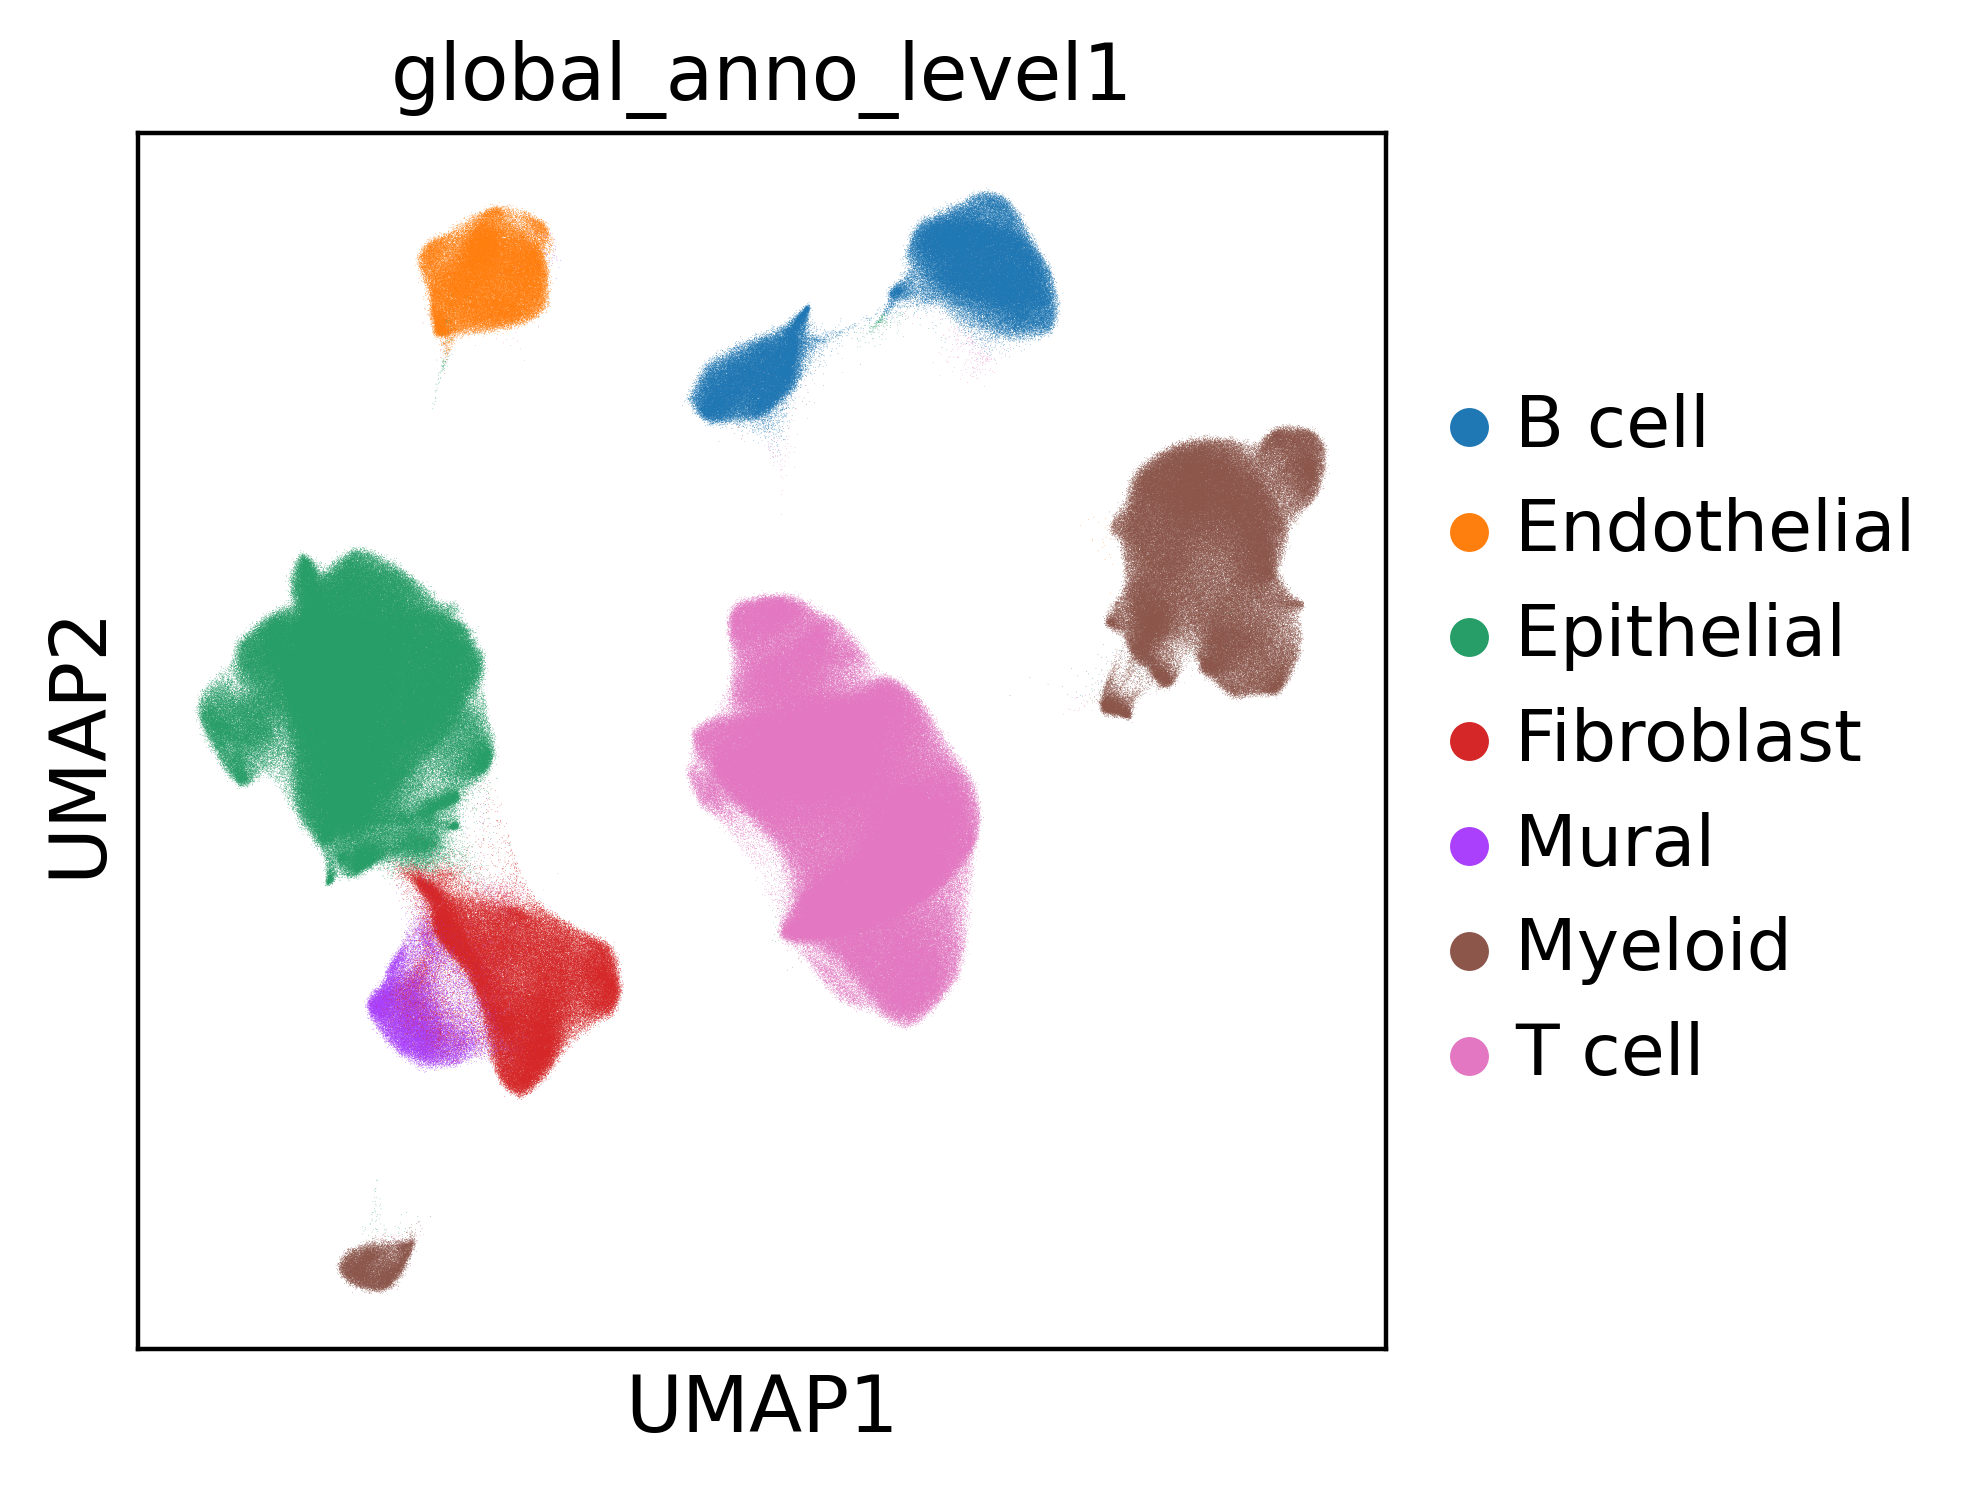

In [3]:
sc.pl.umap(adata,color='global_anno_level1')

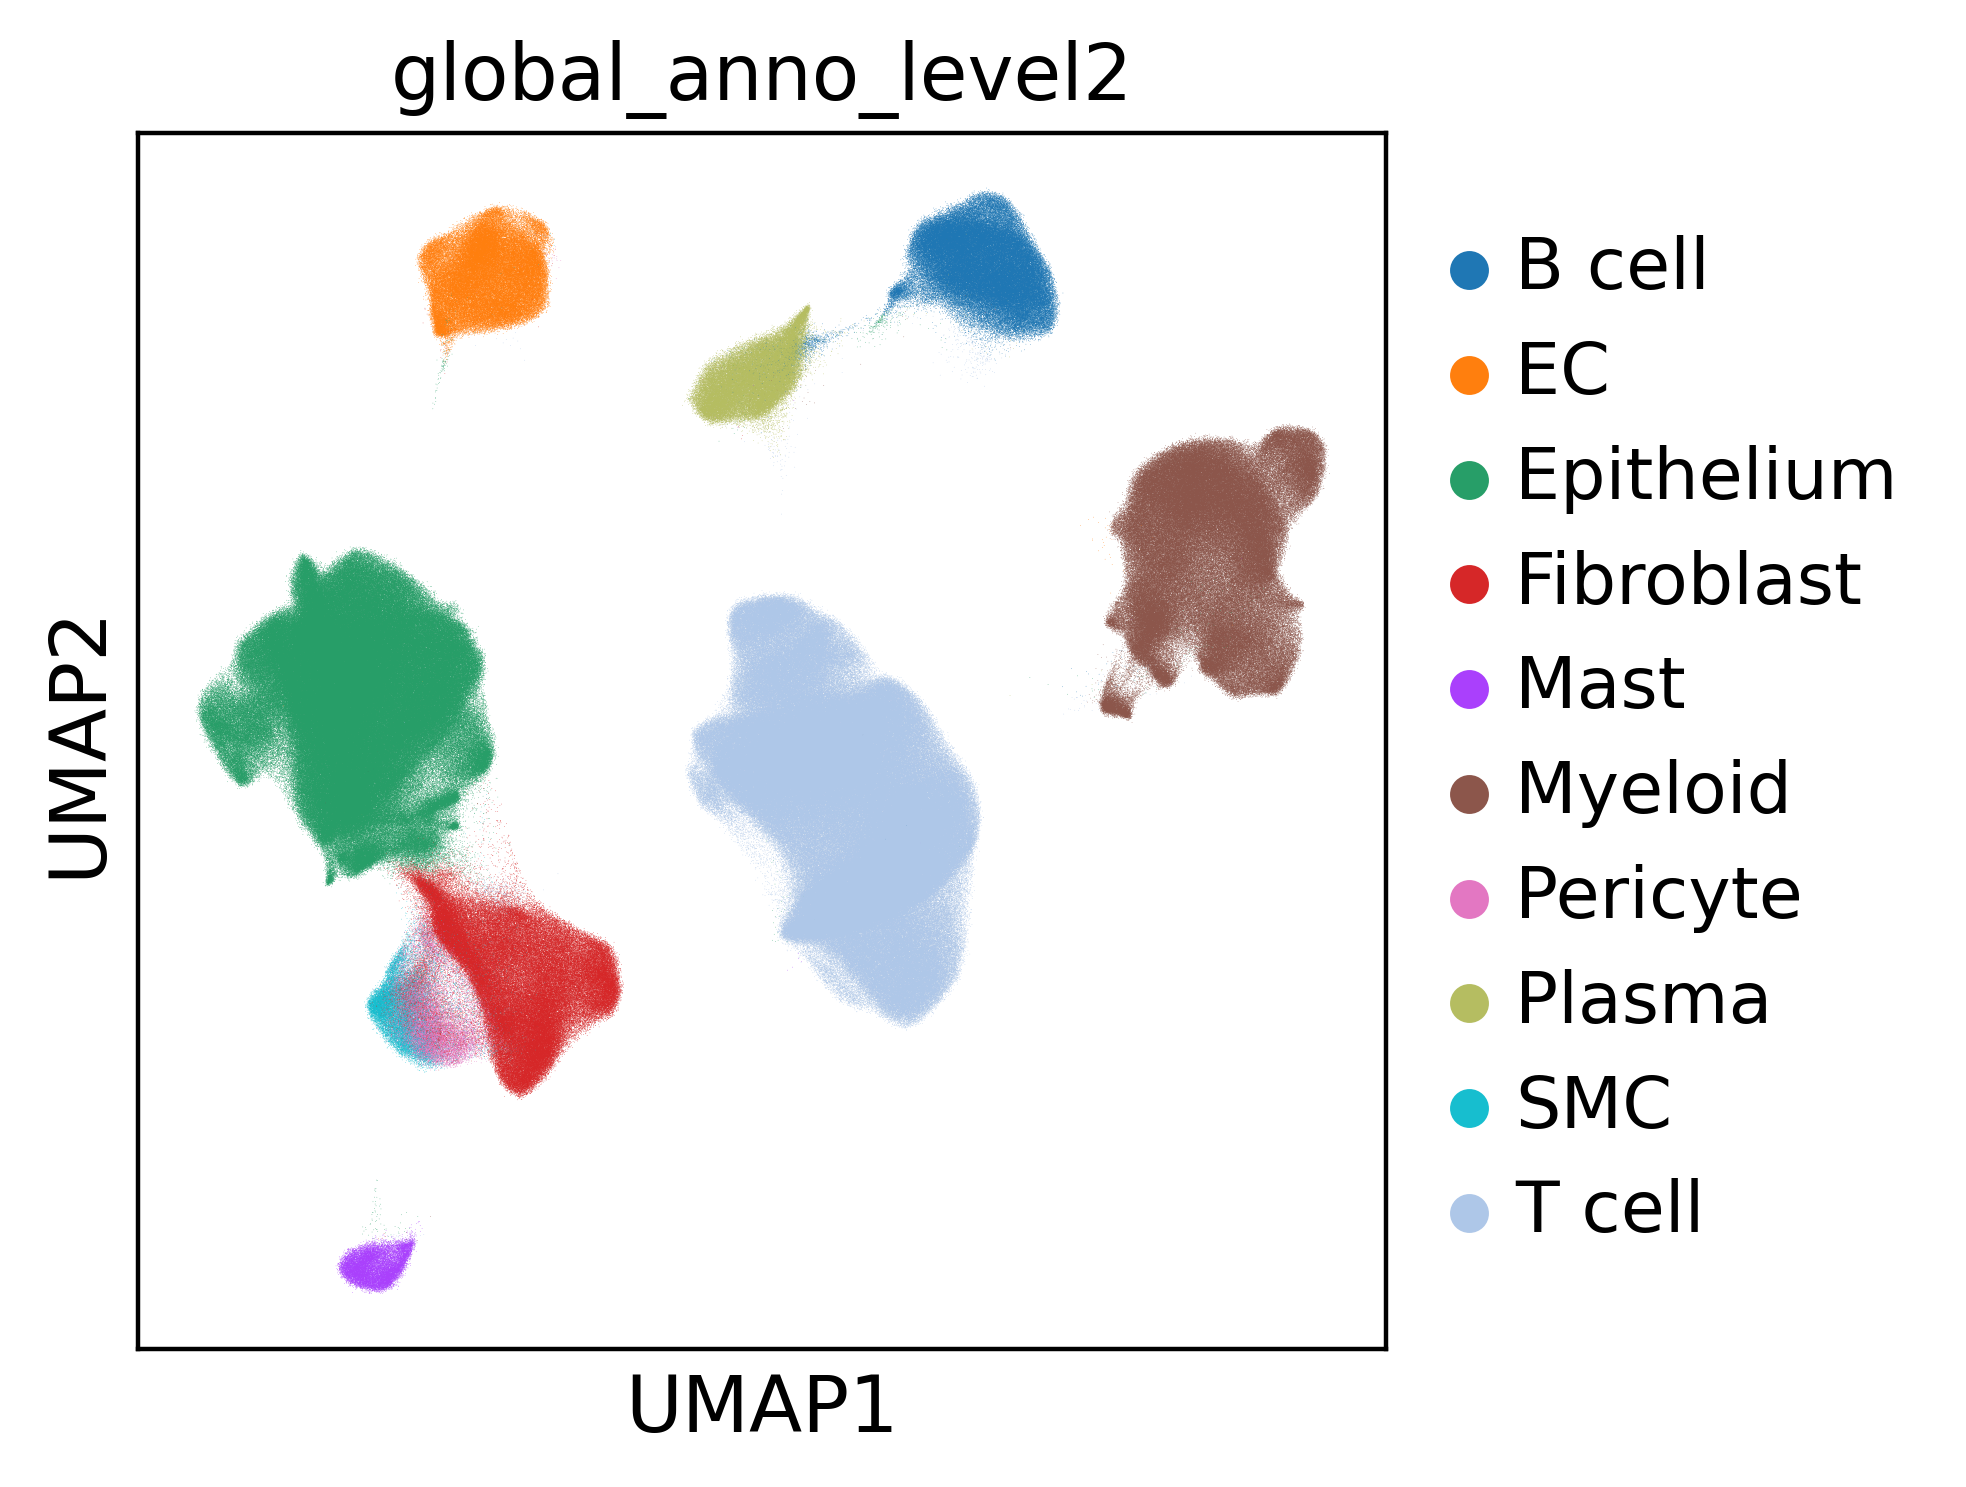

In [4]:
sc.pl.umap(adata,color='global_anno_level2')

# Fig2a

{'Epithelial': '#FF0000', 'T cell': '#0000FF', 'B cell': '#00FF00', 'Myeloid': '#9D00FF', 'Endothelial': '#FF00FF', 'Fibroblast': '#FF9500', 'Mural': '#00FFFF'}


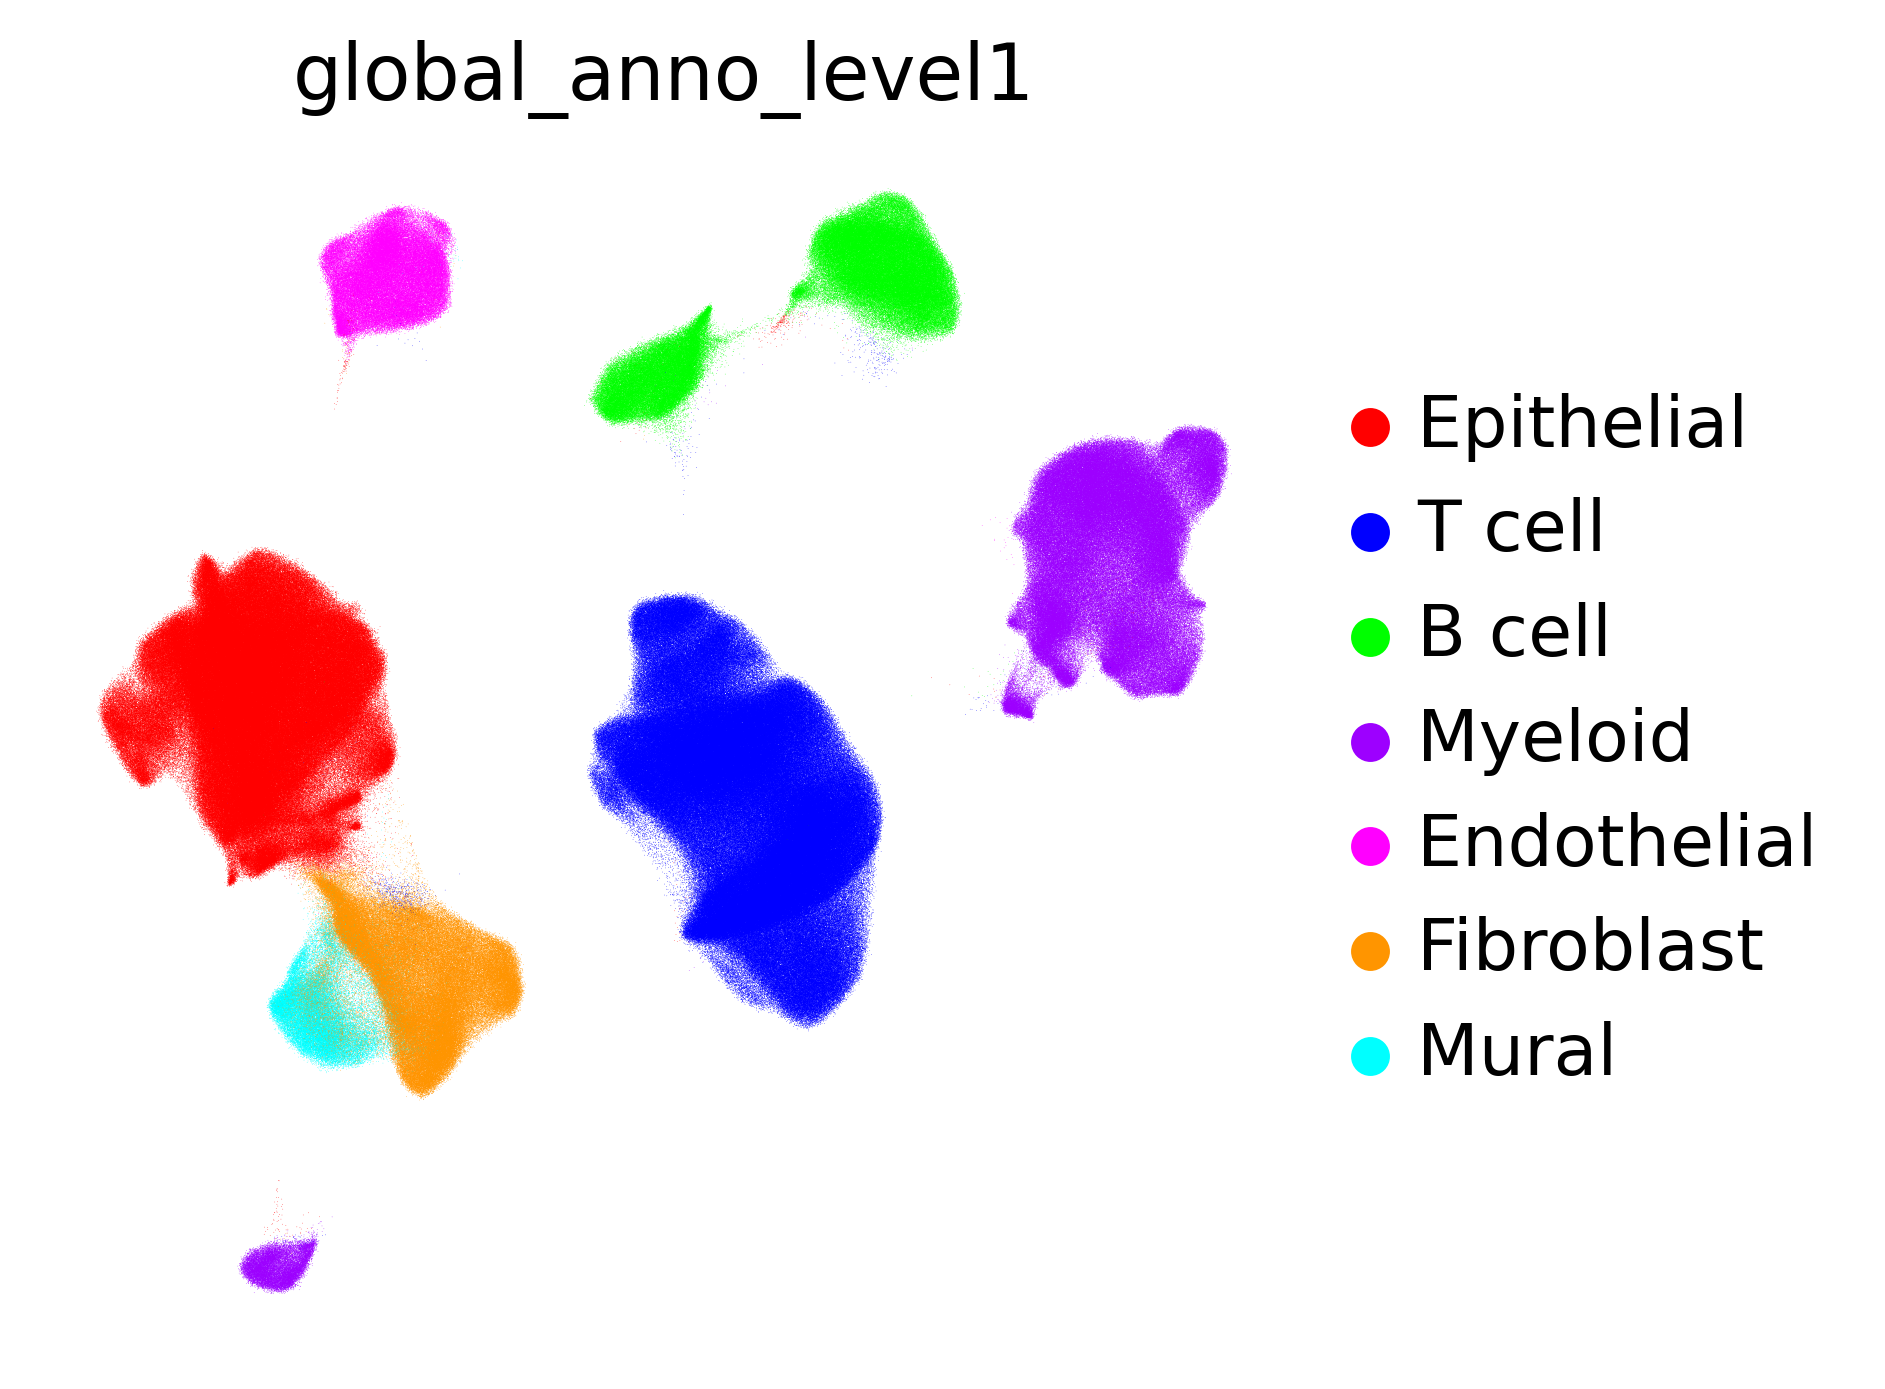

In [5]:
import numpy as np
import pandas as pd

# 1) 색상 매핑 정의 (업로드 이미지와 동일한 색)
color_map = {
    'Epithelial':  '#FF0000',  # red      (그대로 — 이미 최대)
    'T cell':      '#0000FF',  # blue     (그대로 — 이미 최대)
    'B cell':      '#00FF00',  # green    ← #00CC00에서 명도 최대로
    'Myeloid':     '#9D00FF',  # purple   ← #9932CC에서 채도·명도 최대로
    'Endothelial': '#FF00FF',  # magenta  (그대로)
    'Fibroblast':  '#FF9500',  # orange   (거의 동일, 살짝 더 붉게)
    'Mural':       '#00FFFF',  # cyan     (그대로)
}

# 2) categorical 보장
if not isinstance(adata.obs['global_anno_level1'].dtype, pd.CategoricalDtype):
    adata.obs['global_anno_level1'] = adata.obs['global_anno_level1'].astype('category')

# 3) (선택) 범례 순서를 이미지와 동일하게 고정
order = ['Epithelial', 'T cell', 'B cell', 'Myeloid', 'Endothelial', 'Fibroblast', 'Mural']
cats = list(adata.obs['global_anno_level1'].cat.categories)
if set(cats) == set(order):
    adata.obs['global_anno_level1'] = (
        adata.obs['global_anno_level1'].cat.reorder_categories(order)
    )

# 4) 카테고리 순서에 맞춰 색 배열 생성
cats = list(adata.obs['global_anno_level1'].cat.categories)
missing = [c for c in cats if c not in color_map]
assert not missing, f"color_map에 없는 카테고리: {missing}"

adata.uns['global_anno_level1_colors'] = np.array([color_map[c] for c in cats])

# 5) 확인
print(dict(zip(cats, adata.uns['global_anno_level1_colors'])))
sc.pl.umap(adata, color='global_anno_level1',frameon=False)


Cancer_type
BRCA    357581
LUCA    280284
OVCA    240275
STCA    210650
PACA    205454
THCA    199665
HNCA    160993
PRCA    160539
LICA    108217
COCA     99562
KICA     77796
SKCA     44777
UECA     37512
Name: count, dtype: int64
{'BRCA': '#7570B3', 'COCA': '#E7298A', 'UECA': '#66A61E', 'HNCA': '#A6761D', 'KICA': '#666666', 'LICA': '#5C4D8F', 'LUCA': '#FF57C0', 'OVCA': '#8DC244', 'PACA': '#F5C832', 'PRCA': '#8A5510', 'SKCA': '#8A8A8A', 'STCA': '#A999D7', 'THCA': '#CDE67F'}


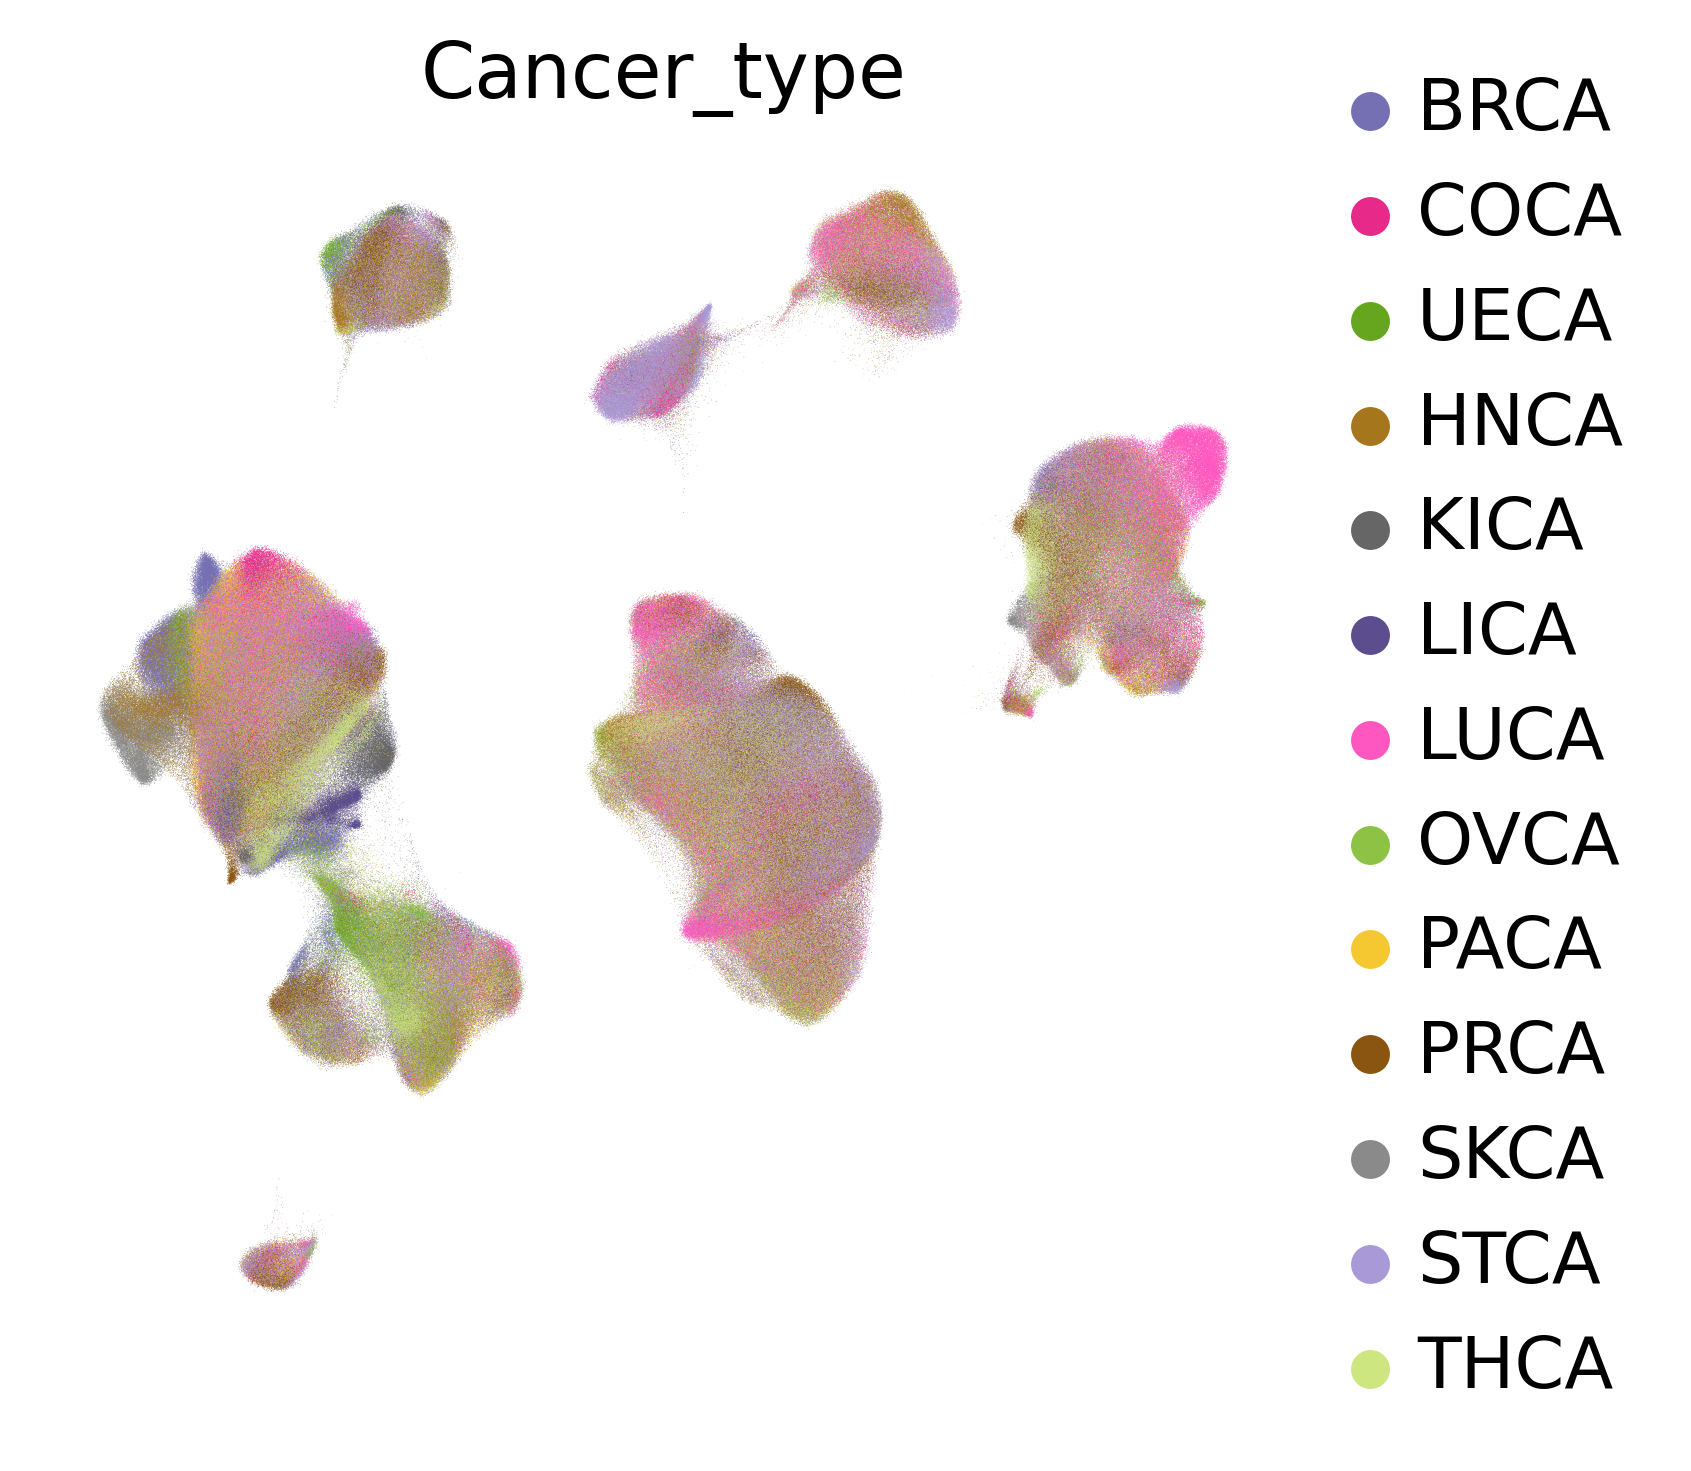

In [6]:
# 1) Organ_orig -> 암종 약어 매핑
organ2cancer = {
    'Breast':        'BRCA',
    'Colorectal':    'COCA',
    'Endometrium':   'UECA',
    'Head and Neck': 'HNCA',
    'Kidney':        'KICA',
    'Liver':         'LICA',
    'Lung':          'LUCA',
    'Ovary':         'OVCA',
    'Pancreas':      'PACA',
    'Prostate':      'PRCA',
    'Skin':          'SKCA',
    'Stomach':       'STCA',
    'Thyroid':       'THCA',
}

# 2) 매핑 안 되는 값이 있는지 먼저 확인
organs = set(adata.obs['Organ_orig'].astype(str).unique())
unmapped = organs - set(organ2cancer)
assert not unmapped, f"매핑 없는 Organ_orig 값: {unmapped}"

# 3) 새 컬럼 생성
adata.obs['Cancer_type'] = (
    adata.obs['Organ_orig'].astype(str).map(organ2cancer).astype('category')
)

# 4) 색상 매핑
cancer_colors = {
    'BRCA' : '#7570B3',
    'COCA' : '#E7298A',
    'UECA' : '#66A61E',
    'HNCA' : '#A6761D',
    'KICA' : '#666666',
    'LICA' : '#5C4D8F',
    'LUCA' : '#FF57C0',
    'OVCA' : '#8DC244',
    'PACA' : '#F5C832',
    'PRCA' : '#8A5510',
    'SKCA' : '#8A8A8A',
    'STCA' : '#A999D7',
    'THCA' : '#CDE67F'
}


# 5) 범례 순서를 위 dict 순서 그대로 고정 (알파벳순 원하면 이 블록 삭제)
order = [c for c in cancer_colors if c in adata.obs['Cancer_type'].cat.categories]
adata.obs['Cancer_type'] = adata.obs['Cancer_type'].cat.reorder_categories(order)

# 6) categories 순서에 맞춰 uns에 색 배열 저장
cats = list(adata.obs['Cancer_type'].cat.categories)
missing = [c for c in cats if c not in cancer_colors]
assert not missing, f"cancer_colors에 없는 카테고리: {missing}"

adata.uns['Cancer_type_colors'] = np.array([cancer_colors[c] for c in cats])

# 7) 확인
print(adata.obs['Cancer_type'].value_counts())
print(dict(zip(cats, adata.uns['Cancer_type_colors'])))

sc.pl.umap(adata, color='Cancer_type', frameon=False)
